In [26]:
# 1. Import & Configuration
###########################################################
import os
import random  # [추가] 랜덤 변환을 위해 필요
from PIL import Image
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF # [추가] 정교한 동기화 변환을 위해 필요
import matplotlib.pyplot as plt

# [설정] 클래스 개수 (0~12번 라벨이 존재하므로 13개)
NUM_CLASSES = 13
BATCH_SIZE = 4
LEARNING_RATE = 0.0001
NUM_EPOCHS = 20  # 어그먼테이션을 하면 데이터가 다양해지므로 Epoch을 조금 늘리는 게 좋습니다.
IMG_SIZE = (512, 512)

###########################################################
# 2. Custom Dataset (Augmentation 추가됨)
###########################################################
class SegDataset(Dataset):
    def __init__(self, root_dir, mode='train'):
        self.img_dir = os.path.join(root_dir, "RGB")
        self.label_dir = os.path.join(root_dir, "Label")

        self.img_list = sorted(os.listdir(self.img_dir))
        self.label_list = sorted(os.listdir(self.label_dir))

        # 이미지는 부드럽게(Bilinear), 라벨은 값 유지(Nearest)
        self.resize_img = transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_label = transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.NEAREST)

        # 이미지 전용: 텐서 변환
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.img_list)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.img_dir, self.img_list[idx])).convert("RGB")

        # 2. 라벨 로드
        label = Image.open(os.path.join(self.label_dir, self.label_list[idx]))

        # 3. 리사이즈
        img = self.resize_img(img)
        label = self.resize_label(label) # 색상이 섞이지 않게 Nearest 사용

        # 4. 텐서 변환 (이미지)
        img_tensor = self.to_tensor(img)

        # 5. 라벨 처리
        label_np = np.array(label)

        # 혹시나 채널 차원(H, W, 1)이 있다면 제거해서 (H, W)로 만듦 -> 3차원을 2차원으로
        if len(label_np.shape) == 3:
            label_np = label_np[:, :, 0]

        label_tensor = torch.from_numpy(label_np).long()

        return img_tensor, label_tensor


In [27]:
# 1. Import & Configuration
###########################################################
import os
import random  # [추가] 랜덤 변환을 위해 필요
from PIL import Image
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF # [추가] 정교한 동기화 변환을 위해 필요
import matplotlib.pyplot as plt

# [설정] 클래스 개수 (0~12번 라벨이 존재하므로 13개)
NUM_CLASSES = 13
BATCH_SIZE = 4
LEARNING_RATE = 0.0001
NUM_EPOCHS = 20
# 이미지 사이즈를 Crop 사이즈로 사용
IMG_SIZE = (512, 512)
CROP_SIZE = IMG_SIZE # [추가] 리사이즈 후 자를 최종 크기

# [설정] Augmentation 확률 및 크기
HFLIP_PROB = 0.5
VFLIP_PROB = 0.1 # 수직 뒤집기는 낮은 확률 권장

###########################################################
# 2. Custom Dataset (Augmentation 추가됨)
###########################################################
class SegDataset_aug(Dataset):
    def __init__(self, root_dir, mode='train'):
        self.img_dir = os.path.join(root_dir, "RGB")
        self.label_dir = os.path.join(root_dir, "Label")

        self.img_list = sorted(os.listdir(self.img_dir))
        self.label_list = sorted(os.listdir(self.label_dir))

        # 리사이즈: Augmentation 전에 수행하여 일정한 크기로 만듦
        self.resize_img = transforms.Resize(CROP_SIZE, interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_label = transforms.Resize(CROP_SIZE, interpolation=transforms.InterpolationMode.NEAREST)

        # 이미지 전용: 텐서 변환 및 정규화 (정규화 추가를 권장)
        self.to_tensor_and_norm = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.img_list)

    def __getitem__(self, idx):
        # 1. 이미지 및 라벨 로드 (PIL Image 형태)
        img = Image.open(os.path.join(self.img_dir, self.img_list[idx])).convert("RGB")
        label = Image.open(os.path.join(self.label_dir, self.label_list[idx]))

        # 2. 리사이즈 (Augmentation 전에 크기 맞추기)
        img = self.resize_img(img)
        label = self.resize_label(label)

        ###########################################################
        # [추가] 3. Data Augmentation
        ###########################################################

        # A. Random Crop: Cropping은 리사이즈 크기(CROP_SIZE)만큼 이미지를 자르는 용도로 사용합니다.
        # (현재는 리사이즈 크기와 같으므로 사실상 랜덤 Crop보다는 일관된 크기 확보의 역할)
        # 만약 원본 이미지보다 작은 CROP_SIZE를 사용하려면, 리사이즈를 더 큰 크기로 하고
        # 이어서 CROP_SIZE만큼 잘라야 효과가 좋습니다. 현재는 생략합니다.
        
        # B. Random Flip (Horizontal & Vertical)
        
        # [추가] 3-1. Random Horizontal Flip
        if random.random() < HFLIP_PROB:
            img = TF.hflip(img)
            label = TF.hflip(label) # 라벨도 동일하게 뒤집기
            
        # [추가] 3-2. Random Vertical Flip
        if random.random() < VFLIP_PROB:
            img = TF.vflip(img)
            label = TF.vflip(label) # 라벨도 동일하게 뒤집기
            
        ###########################################################
        # 4. 텐서 변환 및 라벨 처리
        
        # 4-1. 이미지 텐서 변환 및 정규화
        img_tensor = self.to_tensor_and_norm(img) # [수정] 정규화 포함된 함수 사용

        # 4-2. 라벨 처리 및 텐서 변환
        label_np = np.array(label)

        # 혹시나 채널 차원(H, W, 1)이 있다면 제거해서 (H, W)로 만듦 -> 3차원을 2차원으로
        if len(label_np.shape) == 3:
            label_np = label_np[:, :, 0]

        label_tensor = torch.from_numpy(label_np).long()

        return img_tensor, label_tensor
    


class SegDataset(Dataset):
    def __init__(self, root_dir, mode='train'):
        self.img_dir = os.path.join(root_dir, "RGB")
        self.label_dir = os.path.join(root_dir, "Label")

        self.img_list = sorted(os.listdir(self.img_dir))
        self.label_list = sorted(os.listdir(self.label_dir))

        # 이미지는 부드럽게(Bilinear), 라벨은 값 유지(Nearest)
        self.resize_img = transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_label = transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.NEAREST)

        # 이미지 전용: 텐서 변환
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.img_list)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.img_dir, self.img_list[idx])).convert("RGB")

        # 2. 라벨 로드
        label = Image.open(os.path.join(self.label_dir, self.label_list[idx]))

        # 3. 리사이즈
        img = self.resize_img(img)
        label = self.resize_label(label) # 색상이 섞이지 않게 Nearest 사용

        # 4. 텐서 변환 (이미지)
        img_tensor = self.to_tensor(img)

        # 5. 라벨 처리
        label_np = np.array(label)

        # 혹시나 채널 차원(H, W, 1)이 있다면 제거해서 (H, W)로 만듦 -> 3차원을 2차원으로
        if len(label_np.shape) == 3:
            label_np = label_np[:, :, 0]

        label_tensor = torch.from_numpy(label_np).long()

        return img_tensor, label_tensor


In [ ]:
import torch.optim as optim
import numpy as np

# ==================== Model ====================
NUM_CLASSES = 13

class khaha(nn.Module):
    def __init__(self, num_classes):
        super(khaha, self).__init__()
        self.leaky = nn.LeakyReLU(0.1)

        # ---------- Encoder ----------
        self.conv1_1 = nn.Conv2d(3,64,3,padding=1)
        self.bn1_1 = nn.BatchNorm2d(64)
        self.conv1_2 = nn.Conv2d(64,64,3,padding=1)
        self.bn1_2 = nn.BatchNorm2d(64)
        self.pool1 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

        self.conv2_1 = nn.Conv2d(64,128,3,padding=1)
        self.bn2_1 = nn.BatchNorm2d(128)
        self.conv2_2 = nn.Conv2d(128,128,3,padding=1)
        self.bn2_2 = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

        self.conv3_1 = nn.Conv2d(128,256,3,padding=1)
        self.bn3_1 = nn.BatchNorm2d(256)
        self.conv3_2 = nn.Conv2d(256,256,3,padding=1)
        self.bn3_2 = nn.BatchNorm2d(256)
        self.pool3 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

        self.conv4_1 = nn.Conv2d(256,512,3,padding=1)
        self.bn4_1 = nn.BatchNorm2d(512)
        self.conv4_2 = nn.Conv2d(512,512,3,padding=1)
        self.bn4_2 = nn.BatchNorm2d(512)
        self.pool4 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

        self.conv5_1 = nn.Conv2d(512,1024,3,padding=1)
        self.bn5_1 = nn.BatchNorm2d(1024)
        self.conv5_2 = nn.Conv2d(1024,1024,3,padding=1)
        self.bn5_2 = nn.BatchNorm2d(1024)
        self.pool5 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

        self.conv6 = nn.Conv2d(1024,1024,3,padding=1)
        self.bn6_1 = nn.BatchNorm2d(1024)
        self.conv6_1 = nn.Conv2d(1024,1024,3,padding=1)
        self.bn6_2 = nn.BatchNorm2d(1024)
        self.conv6_2 = nn.Conv2d(1024,1024,3,padding=1)
        self.bn6_3 = nn.BatchNorm2d(1024)
        self.pool6 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

        # ---------- Decoder ----------
        self.upconv5 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec5_1 = nn.Conv2d(1536, 512, 3, padding=1)
        self.bn_dec5_1 = nn.BatchNorm2d(512)
        self.dec5_2 = nn.Conv2d(512, 512, 3, padding=1)
        self.bn_dec5_2 = nn.BatchNorm2d(512)

        self.upconv4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4_1 = nn.Conv2d(768, 256, 3, padding=1)
        self.bn_dec4_1 = nn.BatchNorm2d(256)
        self.dec4_2 = nn.Conv2d(256, 256, 3, padding=1)
        self.bn_dec4_2 = nn.BatchNorm2d(256)

        self.upconv3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3_1 = nn.Conv2d(384, 128, 3, padding=1)
        self.bn_dec3_1 = nn.BatchNorm2d(128)
        self.dec3_2 = nn.Conv2d(128, 128, 3, padding=1)
        self.bn_dec3_2 = nn.BatchNorm2d(128)

        self.upconv2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2_1 = nn.Conv2d(192, 64, 3, padding=1)
        self.bn_dec2_1 = nn.BatchNorm2d(64)
        self.dec2_2 = nn.Conv2d(64, 64, 3, padding=1)
        self.bn_dec2_2 = nn.BatchNorm2d(64)

        self.upconv1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1_1 = nn.Conv2d(96, 32, 3, padding=1)
        self.bn_dec1_1 = nn.BatchNorm2d(32)
        self.dec1_2 = nn.Conv2d(32, 32, 3, padding=1)
        self.bn_dec1_2 = nn.BatchNorm2d(32)

        self.final_conv = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoding
        x = self.leaky(self.bn1_1(self.conv1_1(x)))
        x = self.leaky(self.bn1_2(self.conv1_2(x)))
        skip1 = x
        x = self.pool1(x)

        x = self.leaky(self.bn2_1(self.conv2_1(x)))
        x = self.leaky(self.bn2_2(self.conv2_2(x)))
        skip2 = x
        x = self.pool2(x)

        x = self.leaky(self.bn3_1(self.conv3_1(x)))
        x = self.leaky(self.bn3_2(self.conv3_2(x)))
        skip3 = x
        x = self.pool3(x)

        x = self.leaky(self.bn4_1(self.conv4_1(x)))
        x = self.leaky(self.bn4_2(self.conv4_2(x)))
        skip4 = x
        x = self.pool4(x)

        x = self.leaky(self.bn5_1(self.conv5_1(x)))
        x = self.leaky(self.bn5_2(self.conv5_2(x)))
        skip5 = x
        x = self.pool5(x)

        x = self.leaky(self.bn6_1(self.conv6(x)))
        x = self.leaky(self.bn6_2(self.conv6_1(x)))
        x = self.leaky(self.bn6_3(self.conv6_2(x)))

        # Decoder
        x = self.upconv5(x)
        x = torch.cat((x, skip5), dim=1)
        x = self.leaky(self.bn_dec5_1(self.dec5_1(x)))
        x = self.leaky(self.bn_dec5_2(self.dec5_2(x)))

        x = self.upconv4(x)
        x = torch.cat((x, skip4), dim=1)
        x = self.leaky(self.bn_dec4_1(self.dec4_1(x)))
        x = self.leaky(self.bn_dec4_2(self.dec4_2(x)))

        x = self.upconv3(x)
        x = torch.cat((x, skip3), dim=1)
        x = self.leaky(self.bn_dec3_1(self.dec3_1(x)))
        x = self.leaky(self.bn_dec3_2(self.dec3_2(x)))

        x = self.upconv2(x)
        x = torch.cat((x, skip2), dim=1)
        x = self.leaky(self.bn_dec2_1(self.dec2_1(x)))
        x = self.leaky(self.bn_dec2_2(self.dec2_2(x)))

        x = self.upconv1(x)
        x = torch.cat((x, skip1), dim=1)
        x = self.leaky(self.bn_dec1_1(self.dec1_1(x)))
        x = self.leaky(self.bn_dec1_2(self.dec1_2(x)))

        out = self.final_conv(x)
        return out




In [30]:
# ==================== Loss ====================
def dice_loss(pred, target, smooth=1.0):
    pred = F.softmax(pred, dim=1)
    target_onehot = F.one_hot(target, num_classes=pred.shape[1]).permute(0,3,1,2).float()
    intersection = (pred * target_onehot).sum(dim=(0,2,3))
    union = pred.sum(dim=(0,2,3)) + target_onehot.sum(dim=(0,2,3))
    loss = 1 - ((2. * intersection + smooth) / (union + smooth))
    return loss.mean()

def combo_loss(pred, target, class_weights=None):
    ce = nn.CrossEntropyLoss(weight=class_weights)(pred, target)
    d = dice_loss(pred, target)
    return ce + d

# ==================== Example Training Loop ====================
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = khaha(NUM_CLASSES).to(device)

# 클래스 가중치 예시 (작은 클래스일수록 높게)
class_weights = torch.tensor([1.0,1.0,3.0,3.0,5.0,3.0,1.0,1.0,1.0,1.0,1.0,3.0,3.0]).to(device)

optimizer = optim.AdamW(model.parameters(), lr=1e-3)


# 4. Training Setup
###########################################################
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 사용 중인 디바이스: {device}")

model = khaha(num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_dir = "Training"
val_dir = "Validation"

if os.path.exists(train_dir):
    train_dataset = SegDataset(train_dir, mode='train')
    val_dataset = SegDataset(val_dir, mode='val')

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    print("✅ 데이터 로드 성공!")
else:
    print("🚨 경로 에러: 구글 드라이브 경로를 다시 확인해주세요.")

# ==================== Example Training Loop ====================
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = khaha(NUM_CLASSES).to(device)

# 클래스 가중치 예시 (작은 클래스일수록 높게)
class_weights = torch.tensor([1.0,1.0,3.0,3.0,5.0,3.0,1.0,1.0,1.0,1.0,1.0,3.0,3.0]).to(device)

optimizer = optim.AdamW(model.parameters(), lr=1e-3)

# train_loader, val_loader는 Dataset/DataLoader 준비되어 있어야 함
num_epochs = 15

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:  # train_loader 준비 필요
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = combo_loss(outputs, labels, class_weights)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
    
    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{num_epochs} - Loss: {epoch_loss:.4f}")



🚀 사용 중인 디바이스: cuda
✅ 데이터 로드 성공!
Epoch 1/15 - Loss: 1.6024
Epoch 2/15 - Loss: 0.9554
Epoch 3/15 - Loss: 0.8139
Epoch 4/15 - Loss: 0.7068
Epoch 5/15 - Loss: 0.6344
Epoch 6/15 - Loss: 0.5890
Epoch 7/15 - Loss: 0.5417
Epoch 8/15 - Loss: 0.4793
Epoch 9/15 - Loss: 0.4252
Epoch 10/15 - Loss: 0.4085
Epoch 11/15 - Loss: 0.3626
Epoch 12/15 - Loss: 0.3506
Epoch 13/15 - Loss: 0.3261
Epoch 14/15 - Loss: 0.3093
Epoch 15/15 - Loss: 0.2900


📸 커스텀 색상으로 결과 시각화 중...


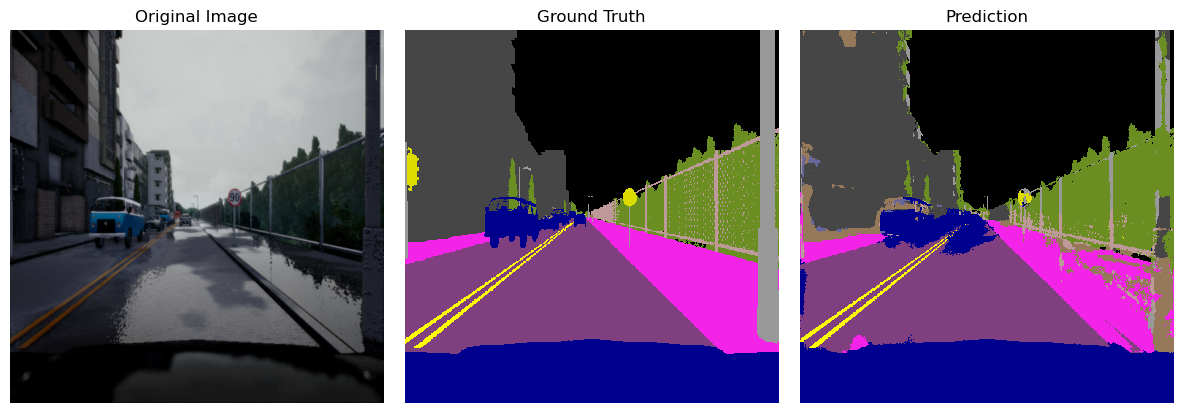

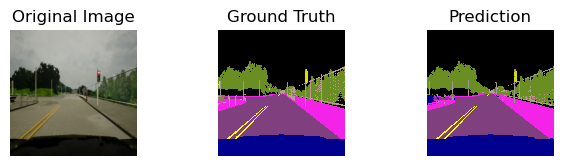

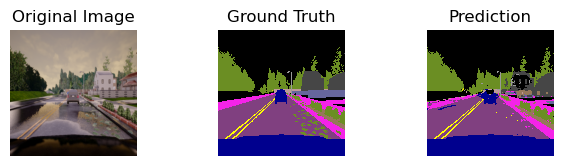

In [31]:
############시각화############3
from matplotlib.colors import ListedColormap

def visualize_predictions(model, val_loader, device, num_samples=3):
  model.eval()

  # ---------------------------------------------------------
  # [1] 사용자 정의 색상표 (0~255 RGB -> 0.0~1.0 Normalize)
  # ---------------------------------------------------------
  custom_colors = [
    [0, 0, 0],          # 0 None
    [70, 70, 70],       # 1 Buildings
    [190, 153, 153],    # 2 Fences
    [150, 120, 90],     # 3 Other
    [220, 20, 60],      # 4 Pedestrians
    [153, 153, 153],    # 5 Poles
    [255, 255, 0],      # 6 RoadLines
    [128, 64, 128],     # 7 Roads
    [244, 35, 232],     # 8 Sidewalks
    [107, 142, 35],     # 9 Vegetation
    [0, 0, 142],        # 10 Vehicles
    [102, 102, 156],    # 11 Walls
    [220, 220, 0],      # 12 TrafficSigns
    ]

  # 리스트를 numpy 배열로 바꾸고 255로 나누어 0~1 사이 값으로 변환
  cmap_np = np.array(custom_colors) / 255.0

  # Matplotlib 전용 컬러맵 객체 생성
  custom_cmap = ListedColormap(cmap_np)

  # ---------------------------------------------------------
  # [2] 데이터 로드 및 추론
  # ---------------------------------------------------------
  
  imgs_all = []
  labels_all = []
  
  for imgs, labels in val_loader:
        imgs_all.append(imgs)
        labels_all.append(labels)
  imgs_all = torch.cat(imgs_all, dim=0)
  labels_all = torch.cat(labels_all, dim=0)

  # 랜덤 인덱스로 num_samples개 선택
  indices = np.random.choice(len(imgs_all), num_samples, replace=False)
  imgs = imgs_all[indices].to(device)
  labels = labels_all[indices].to(device)

  with torch.no_grad():
    outputs = model(imgs)
    preds = torch.argmax(outputs, dim=1) # (B, H, W)

  # CPU 이동
  imgs = imgs.cpu()
  labels = labels.cpu()
  preds = preds.cpu()

  # ---------------------------------------------------------
  # [3] 시각화 (Plotting)
  # ---------------------------------------------------------
  plt.figure(figsize=(12, 4 * num_samples))

  for i in range(num_samples):
    img_np = imgs[i].permute(1, 2, 0).numpy()
    label_np = labels[i].numpy()
    pred_np = preds[i].numpy()

    # (1) 원본 이미지
    plt.subplot(num_samples, 3, i*3 + 1)
    plt.imshow(img_np)
    plt.title("Original Image")
    plt.axis('off')

    # (2) 정답 라벨 (커스텀 컬러맵 적용)
    plt.subplot(num_samples, 3, i*3 + 2)
    plt.imshow(label_np, cmap=custom_cmap, vmin=0, vmax=NUM_CLASSES-1, interpolation='nearest')
    plt.title("Ground Truth")
    plt.axis('off')

    # (3) 모델 예측 (커스텀 컬러맵 적용)
    plt.subplot(num_samples, 3, i*3 + 3)
    plt.imshow(pred_np, cmap=custom_cmap, vmin=0, vmax=NUM_CLASSES-1, interpolation='nearest')
    plt.title("Prediction")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# 실행
print("📸 커스텀 색상으로 결과 시각화 중...")
visualize_predictions(model, val_loader, device, num_samples=3)

In [32]:
# ================= [2] 검증 및 IoU 계산 (Validation) =================
model.eval() # 평가 모드 전환 (Dropout 등 비활성화)
val_loss = 0

# 전체 데이터셋에 대한 교집합(intersection)과 합집합(union)을 저장할 변수
# 클래스 개수만큼 0으로 초기화
total_intersection = torch.zeros(NUM_CLASSES).to(device)
total_union = torch.zeros(NUM_CLASSES).to(device)

with torch.no_grad():
    for img, label in val_loader:
        img, label = img.to(device), label.to(device)

        output = model(img) # (B, C, H, W)
        loss = criterion(output, label)
        val_loss += loss.item()

        # ---------------- IoU 계산 로직 시작 ----------------
        # (B, C, H, W) -> (B, H, W) : 가장 높은 확률을 가진 클래스 인덱스 선택
        preds = torch.argmax(output, dim=1)

        for cls in range(NUM_CLASSES):
            # 특정 클래스(cls)에 대한 마스크 생성 (True/False)
            pred_mask = (preds == cls)
            true_mask = (label == cls)

            # 교집합 (AND 연산): 둘 다 True인 픽셀 수
            intersection = (pred_mask & true_mask).sum()

            # 합집합 (OR 연산): 둘 중 하나라도 True인 픽셀 수
            union = (pred_mask | true_mask).sum()

            # 누적
            total_intersection[cls] += intersection
            total_union[cls] += union
        # ---------------- IoU 계산 로직 끝 -----------------

avg_val_loss = val_loss / len(val_loader)

# 에폭마다 결과 출력
print(f"\n[Epoch {epoch+1}/{NUM_EPOCHS}]")
print(f"Val Loss: {avg_val_loss:.4f}")
print("-" * 50)
print("  📊 Class-wise IoU:")

miou_list = []
for cls in range(NUM_CLASSES):
    # 분모가 0이면(해당 클래스가 아예 없으면) 계산 제외
    if total_union[cls] == 0:
        iou = 0.0
    else:
        iou = total_intersection[cls] / total_union[cls]
        miou_list.append(iou.item())

    # 클래스별 IoU 출력
    print(f"    Class {cls}: {iou:.4f}")

# 전체 평균 IoU (mIoU) 계산
if len(miou_list) > 0:
    miou = sum(miou_list) / len(miou_list)
    print(f"  🏆 mIoU (Mean IoU): {miou:.4f}")
else:
    print("  🏆 mIoU: 0.0000")
print("=" * 50)

print("🎉 모든 학습이 완료되었습니다!")
torch.save(model.state_dict(), "fcn16_multi_class_aug.pth")


[Epoch 15/20]
Val Loss: 0.7801
--------------------------------------------------
  📊 Class-wise IoU:
    Class 0: 0.8718
    Class 1: 0.7482
    Class 2: 0.2607
    Class 3: 0.1237
    Class 4: 0.0000
    Class 5: 0.2658
    Class 6: 0.6791
    Class 7: 0.7831
    Class 8: 0.6641
    Class 9: 0.7548
    Class 10: 0.8488
    Class 11: 0.2690
    Class 12: 0.4404
  🏆 mIoU (Mean IoU): 0.5161
🎉 모든 학습이 완료되었습니다!
